# IADS5 · TP integrador — Ortelana Textil
### Actividad 02 · Métricas de la baseline

**Integrantes del grupo:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma  
**Comisión:** [Completar]  
**Repositorio GitHub:** [URL]  
**Fecha:** 31/10/2026

> Notebook independiente. Requiere el archivo `particion_train_test.csv` (partición train/test generada por `actividad_01.ipynb`).

## Actividad 02 · Métricas de la baseline

**Qué se espera:** Calculá accuracy, F1 y métricas por clase para clasificación; para la tarea de regresión calculá MAE, MSE, RMSE y R². Mostrá una tabla y la distribución del target.

**Evidencia a entregar:** Tabla de métricas y visualización del target.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de versión de librerías
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("ventas_historicas_ortelana_argentina.csv")

# Partición de la actividad 01: misma semilla, mismas filas de train y test
target = "Format_Reporte"
features = ["Sucursal_ID", "Tela_ID", "Año", "Metros1", "Metros2"]
train, test = train_test_split(df, test_size=0.2, stratify=df[target], random_state=RANDOM_STATE)

# Control: tiene que coincidir con la partición guardada en particion_train_test.csv
particion = pd.read_csv("particion_train_test.csv", index_col="fila")["particion"]
assert (particion[test.index] == "test").all() and (particion == "test").sum() == len(test)

X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]

# Regresión de Metros2: mismas filas de train y test
features_reg = ["Sucursal_ID", "Tela_ID", "Año", "Metros1"]
Xr_train, Xr_test = train[features_reg], test[features_reg]
yr_train, yr_test = train["Metros2"], test["Metros2"]

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (2628, 5) | Test: (657, 5)


In [2]:
# 2.1 Baselines de la actividad 01
from sklearn.dummy import DummyClassifier, DummyRegressor

pred_base_clf = DummyClassifier(strategy="most_frequent").fit(X_train, y_train).predict(X_test)
pred_base_reg = DummyRegressor(strategy="mean").fit(Xr_train, yr_train).predict(Xr_test)

In [3]:
# 2.2 Métricas de la baseline de clasificación (test)
from sklearn.metrics import accuracy_score, f1_score, classification_report

print("Accuracy:    ", round(accuracy_score(y_test, pred_base_clf), 4))
print("F1 macro:    ", round(f1_score(y_test, pred_base_clf, average="macro"), 4))
print("F1 ponderado:", round(f1_score(y_test, pred_base_clf, average="weighted"), 4))

# Métricas por clase (precision, recall, F1 y soporte)
reporte = classification_report(y_test, pred_base_clf, zero_division=0, output_dict=True)
pd.DataFrame(reporte).T.round(4)

Accuracy:     0.2831
F1 macro:     0.1103
F1 ponderado: 0.1249


,precision,recall,f1-score,support
B,0.0000,0.0000,0.0000,146.0000
C,0.0000,0.0000,0.0000,172.0000
M,0.0000,0.0000,0.0000,153.0000
S,0.2831,1.0000,0.4413,186.0000
accuracy,0.2831,0.2831,0.2831,0.2831
macro avg,0.0708,0.2500,0.1103,657.0000
weighted avg,0.0801,0.2831,0.1249,657.0000


In [4]:
# 2.3 Métricas de la baseline de regresión (test, en metros)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mse = mean_squared_error(yr_test, pred_base_reg)
pd.DataFrame({"MAE": [mean_absolute_error(yr_test, pred_base_reg)],
              "MSE": [mse],
              "RMSE": [np.sqrt(mse)],
              "R2": [r2_score(yr_test, pred_base_reg)]}, index=["Baseline (media)"]).round(4)

,MAE,MSE,RMSE,R2
Baseline (media),695.9745,853337.7914,923.7628,-0.0036


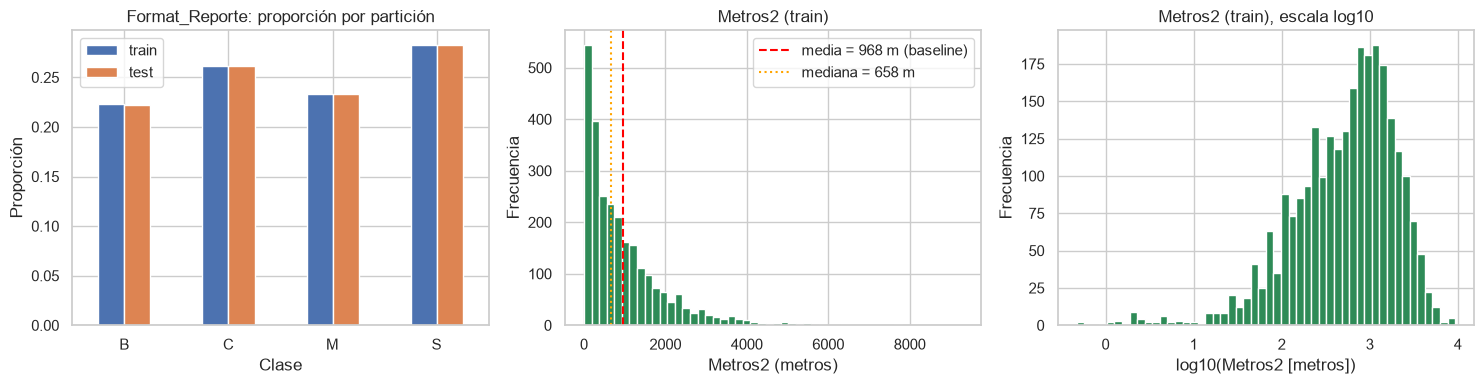

In [5]:
# 2.4 Distribución de los targets
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

proporciones = pd.DataFrame({"train": y_train.value_counts(normalize=True),
                             "test": y_test.value_counts(normalize=True)}).sort_index()
proporciones.plot(kind="bar", rot=0, ax=axes[0])
axes[0].set(title="Format_Reporte: proporción por partición", xlabel="Clase", ylabel="Proporción")

axes[1].hist(yr_train, bins=50, color="seagreen")
axes[1].axvline(yr_train.mean(), color="red", ls="--", label=f"media = {yr_train.mean():.0f} m (baseline)")
axes[1].axvline(yr_train.median(), color="orange", ls=":", label=f"mediana = {yr_train.median():.0f} m")
axes[1].set(title="Metros2 (train)", xlabel="Metros2 (metros)", ylabel="Frecuencia")
axes[1].legend()

axes[2].hist(np.log10(yr_train), bins=50, color="seagreen")
axes[2].set(title="Metros2 (train), escala log10", xlabel="log10(Metros2 [metros])", ylabel="Frecuencia")

plt.tight_layout()
plt.show()

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **Clasificación:** reportamos accuracy, F1 macro y F1 ponderado, y además precision, recall y F1 por clase.
- **F1 macro como métrica principal:** promedia las 4 clases con el mismo peso, así que no premia predecir siempre la clase mayoritaria.
- **Regresión:** reportamos MAE, MSE, RMSE y R², todos en metros salvo el MSE (metros²) y el R², que no tiene unidad. Todas las métricas se calculan sobre test con las predicciones de la baseline de la Actividad 01.

**Interpretación de los resultados:**
- **Baseline de clasificación:** como siempre predice "S", acierta el 28,3% (accuracy 0,2831), que es justo la proporción de S en test. El F1 macro es 0,1103: S tiene recall 1 y F1 0,44, y las otras tres clases tienen F1 = 0.
- **Baseline de regresión:**
  - MAE = 696 m y RMSE = 924 m.
  - R² ≈ 0 (−0,0036): predecir la media de train no explica nada de la variabilidad de test, y el R² queda apenas negativo porque la media de test no coincide exactamente con la de train.
- **Distribución de `Metros2`:** es muy asimétrica a la derecha (mediana ~658 m < media 968 m), y en escala log se ve más simétrica.
- **Piso a superar:** estos números son el mínimo para cualquier modelo.

**Pregunta de análisis:** ¿Un F1=0,80 sería suficiente? ¿Qué costo tienen los errores en las distintas clases? ¿Cómo interpretás RMSE en la regresión elegida?
- **F1 = 0,80:** sería 7 veces mejor que la baseline (0,11), pero que alcance o no depende del uso. Si el formato se usa para saber cuántos períodos esperar y cómo leer el reporte, equivocarse en 1 de cada 5 registros sigue siendo mucho.
- **Costo de los errores:**
  - No es lo mismo confundir un formato de baja frecuencia (semestral o ciclo estacional, 2 períodos) con uno de alta frecuencia (mensual o bimestral, 6–12 períodos), que cambia la estructura esperada del reporte, que confundir semestral con ciclo estacional, que tienen la misma cantidad de columnas.
  - Sin una matriz de costos de negocio, tratamos las clases por igual (F1 macro).
- **RMSE:** es el error "típico" en metros, pero penaliza más los errores grandes. Con la baseline, el RMSE (924 m) es mucho mayor que el MAE (696 m) porque la distribución tiene una cola de registros de alto volumen. Para Ortelana significa que el error lo dominan las combinaciones de mayor venta.

**Limitaciones o mejoras posibles:**
- La baseline de clase mayoritaria no usa ninguna variable.
- Para la regresión también se podría comparar contra la mediana (más robusta a la asimetría) o modelar `log(Metros2)`.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]
